# Holdings pipeline: demo with results
Practice project with **synthetic data**. It loads fund holdings files from two asset managers, checks them, enriches them with reference data, and produces an **exception report**. All functions are tested with `pytest`.

## Case 1: portfolio report
Load one holdings file, check required columns and missing fields, then compute exposures by asset class.

In [1]:
import pandas as pd
from portfolio_report import load_portfolio, build_summary, find_missing_fields

portfolio = load_portfolio("portfolio.csv")
summary = build_summary(portfolio)
print(f"Reporting date: {summary['report_date']}")
print(f"Positions: {summary['positions']}")
print(f"Total value: EUR {summary['total_value_eur']:,.0f}")
print(f"Rows with missing fields: {summary['rows_with_missing_fields']}")
summary["exposures"]

Reporting date: 2026-09-30
Positions: 8
Total value: EUR 9,600,000
Rows with missing fields: 1


,asset_class,market_value_eur,weight_pct
0,Government Bond,4300000.0,44.79
1,Equity,2600000.0,27.08
2,Corporate Bond,2100000.0,21.88
3,Fund,600000.0,6.25


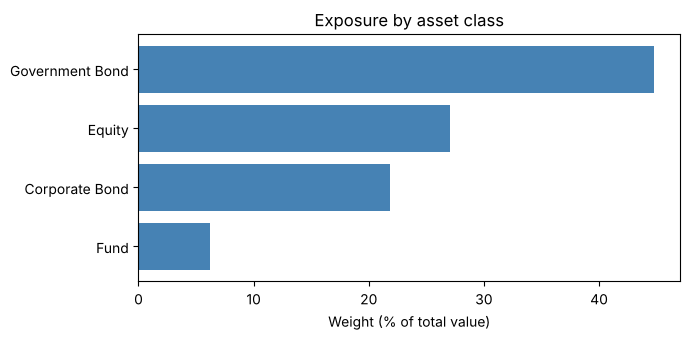

In [2]:
import matplotlib.pyplot as plt
exp = summary["exposures"]
plt.figure(figsize=(7, 3.5))
plt.barh(exp["asset_class"], exp["weight_pct"], color="steelblue")
plt.xlabel("Weight (% of total value)")
plt.title("Exposure by asset class")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Rows to fix before reporting** (never guessed or deleted, they go to the exception list):

In [3]:
find_missing_fields(portfolio)[["position_id", "security_name", "market_value_eur"]]

,position_id,security_name,market_value_eur
7,P008,Unknown security,NaN


## Case 2: consolidate two managers' files
Manager A sends a CSV (semicolons, decimal commas, dd/mm/yyyy dates); manager B sends an Excel file. Both are mapped to one standard schema, enriched with a **left join** on the ISIN, converted to EUR, and checked.

In [4]:
from consolidate import run

reference = pd.DataFrame({
    "isin": ["FR0000000001", "US0000000004", "DE0000000002", "GB0000000009", "FR0000000005"],
    "issuer": ["French Republic", "Corp B", "Federal Republic of Germany", "Corp E", "Company C"],
    "asset_class": ["Government Bond", "Corporate Bond", "Government Bond", "Corporate Bond", "Equity"],
    "rating": ["AA-", "BBB", "AAA", None, None],
})
fx = pd.DataFrame({"currency": ["EUR", "USD"],
                   "report_date": pd.to_datetime(["2026-09-30"] * 2),
                   "eur_rate": [1.0, 1.10]})   # GBP rate missing on purpose

clean, exceptions = run("manager_a.csv", "manager_b.xlsx", reference, fx)
clean[["source", "isin", "market_value", "currency", "market_value_eur", "asset_class", "rating"]].round(2)

,source,isin,market_value,currency,market_value_eur,asset_class,rating
0,manager_a,FR0000000001,1250000.5,EUR,1250000.50,Government Bond,AA-
1,manager_a,US0000000004,600000.0,USD,545454.55,Corporate Bond,BBB
3,manager_b,DE0000000002,400000.0,EUR,400000.00,Government Bond,AAA


**Exception report**: everything that must be checked before the report is sent.

In [5]:
exceptions[["source", "isin", "currency", "exception"]]

,source,isin,currency,exception
0,manager_a,XX123,EUR,isin not found in reference data
1,manager_b,FR0000000005,EUR,missing market value
2,manager_b,GB0000000009,GBP,missing FX rate
3,manager_a,XX123,EUR,invalid ISIN length


## Tests
All rules are covered by automated tests.

In [6]:
import subprocess
print(subprocess.run(["python", "-m", "pytest", "-q"], capture_output=True, text=True).stdout)

.................                                                        [100%]
17 passed in 0.31s

